<a href="https://colab.research.google.com/github/WhySoSerious404/trust-safety-analytics/blob/main/01-fraud-detection/fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [10]:
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Project: trust-safety/fraud_oracle.csv')
#print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Exploration

In [11]:
df.head(10)

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision
5,Oct,4,Friday,Honda,Urban,Wednesday,Nov,1,Male,Single,...,5 years,21 to 25,No,No,External,3 to 5,no change,1 vehicle,1994,Collision
6,Feb,1,Saturday,Honda,Urban,Monday,Feb,3,Male,Married,...,7 years,36 to 40,No,No,External,1 to 2,no change,1 vehicle,1994,Collision
7,Nov,1,Friday,Honda,Urban,Tuesday,Mar,4,Male,Single,...,new,16 to 17,No,No,External,none,no change,1 vehicle,1994,Collision
8,Dec,4,Saturday,Honda,Urban,Wednesday,Dec,5,Male,Single,...,6 years,31 to 35,No,Yes,External,3 to 5,no change,1 vehicle,1994,Collision
9,Apr,3,Tuesday,Ford,Urban,Wednesday,Apr,3,Male,Married,...,more than 7,36 to 40,No,No,External,3 to 5,no change,1 vehicle,1994,All Perils


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

In [13]:
df.isna().sum()

,0
Month,0
WeekOfMonth,0
DayOfWeek,0
Make,0
AccidentArea,0
DayOfWeekClaimed,0
MonthClaimed,0
WeekOfMonthClaimed,0
Sex,0
MaritalStatus,0


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.00,3.0,4.00,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.00,3.0,4.00,5.0
Age,15420.0,39.855707,13.492377,0.0,31.00,38.0,48.00,80.0
FraudFound_P,15420.0,0.059857,0.237230,0.0,0.00,0.0,0.00,1.0
PolicyNumber,15420.0,7710.500000,4451.514911,1.0,3855.75,7710.5,11565.25,15420.0
RepNumber,15420.0,8.483268,4.599948,1.0,5.00,8.0,12.00,16.0
Deductible,15420.0,407.704280,43.950998,300.0,400.00,400.0,400.00,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.00,2.0,3.00,4.0
Year,15420.0,1994.866472,0.803313,1994.0,1994.00,1995.0,1996.00,1996.0


In [15]:
# Count records whose age is zero
zero_age_count = df["Age"].eq(0).sum()

print("Records with age 0:", zero_age_count)
print(f"Percentage with age 0: {zero_age_count / len(df):.2%}")

Records with age 0: 320
Percentage with age 0: 2.08%


In [16]:
# Inspect every observed value and its frequency
for column in ["Deductible", "DriverRating", "Year"]:
    print(f"\n{column}")
    print(df[column].value_counts().sort_index())


Deductible
Deductible
300        8
400    14838
500      263
700      311
Name: count, dtype: int64

DriverRating
DriverRating
1    3944
2    3801
3    3884
4    3791
Name: count, dtype: int64

Year
Year
1994    6142
1995    5195
1996    4083
Name: count, dtype: int64


In [17]:
df.loc[df["Age"].eq(0), "AgeOfPolicyHolder"].value_counts()

,count
AgeOfPolicyHolder,
16 to 17,320


In [18]:
df.loc[
    df["AgeOfPolicyHolder"].eq("16 to 17"),
    "Age"
].value_counts().sort_index()

,count
Age,
0,320


In [19]:
df["Age"].value_counts().sort_index()

,count
Age,
0,320
16,9
17,6
18,48
19,32
...,...
76,42
77,29
78,35


In [20]:
df.groupby("AgeOfPolicyHolder")["Age"].agg(
    ["count", "min", "max"]
)

,count,min,max
AgeOfPolicyHolder,,,
16 to 17,320,0,0
18 to 20,15,16,17
21 to 25,108,18,20
26 to 30,613,21,25
31 to 35,5593,26,35
36 to 40,4043,36,45
41 to 50,2828,46,55
51 to 65,1392,56,65
over 65,508,66,80


In [21]:
df["FraudFound_P"].value_counts().sort_index()

,count
FraudFound_P,
0,14497
1,923


In [22]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate rows excluding PolicyNumber:",
    df.drop(columns="PolicyNumber").duplicated().sum()
)

print("Unique policy numbers:", df["PolicyNumber"].nunique())

Exact duplicate rows: 0
Duplicate rows excluding PolicyNumber: 0
Unique policy numbers: 15420


In [23]:
df.describe(include="object").T

,count,unique,top,freq
Month,15420,12,Jan,1411
DayOfWeek,15420,7,Monday,2616
Make,15420,19,Pontiac,3837
AccidentArea,15420,2,Urban,13822
DayOfWeekClaimed,15420,8,Monday,3757
MonthClaimed,15420,13,Jan,1446
Sex,15420,2,Male,13000
MaritalStatus,15420,4,Married,10625
Fault,15420,2,Policy Holder,11230
PolicyType,15420,9,Sedan - Collision,5584


In [24]:
df["DayOfWeekClaimed"].value_counts(dropna=False)

,count
DayOfWeekClaimed,
Monday,3757
Tuesday,3375
Wednesday,2951
Thursday,2660
Friday,2497
Saturday,127
Sunday,52
0,1


In [25]:
df["MonthClaimed"].value_counts(dropna=False)

,count
MonthClaimed,
Jan,1446
May,1411
Mar,1348
Oct,1339
Jun,1293
Feb,1287
Nov,1285
Apr,1271
Sep,1242


In [26]:
invalid_day = df["DayOfWeekClaimed"].astype(str).eq("0")
invalid_month = df["MonthClaimed"].astype(str).eq("0")

df.loc[
    invalid_day | invalid_month,
    ["Month", "DayOfWeek", "MonthClaimed",
     "DayOfWeekClaimed", "WeekOfMonthClaimed"]
]

,Month,DayOfWeek,MonthClaimed,DayOfWeekClaimed,WeekOfMonthClaimed
1516,Jul,Monday,0,0,1


In [27]:
for column in df.select_dtypes(include="object").columns:
    print(f"\n{column}:")
    print(df[column].unique())


Month:
['Dec' 'Jan' 'Oct' 'Jun' 'Feb' 'Nov' 'Apr' 'Mar' 'Aug' 'Jul' 'May' 'Sep']

DayOfWeek:
['Wednesday' 'Friday' 'Saturday' 'Monday' 'Tuesday' 'Sunday' 'Thursday']

Make:
['Honda' 'Toyota' 'Ford' 'Mazda' 'Chevrolet' 'Pontiac' 'Accura' 'Dodge'
 'Mercury' 'Jaguar' 'Nisson' 'VW' 'Saab' 'Saturn' 'Porche' 'BMW' 'Mecedes'
 'Ferrari' 'Lexus']

AccidentArea:
['Urban' 'Rural']

DayOfWeekClaimed:
['Tuesday' 'Monday' 'Thursday' 'Friday' 'Wednesday' 'Saturday' 'Sunday'
 '0']

MonthClaimed:
['Jan' 'Nov' 'Jul' 'Feb' 'Mar' 'Dec' 'Apr' 'Aug' 'May' 'Jun' 'Sep' 'Oct'
 '0']

Sex:
['Female' 'Male']

MaritalStatus:
['Single' 'Married' 'Widow' 'Divorced']

Fault:
['Policy Holder' 'Third Party']

PolicyType:
['Sport - Liability' 'Sport - Collision' 'Sedan - Liability'
 'Utility - All Perils' 'Sedan - All Perils' 'Sedan - Collision'
 'Utility - Collision' 'Utility - Liability' 'Sport - All Perils']

VehicleCategory:
['Sport' 'Utility' 'Sedan']

VehiclePrice:
['more than 69000' '20000 to 29000' '30000 to 39

In [28]:
for column in ["Days_Policy_Accident", "Days_Policy_Claim"]:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


Days_Policy_Accident
Days_Policy_Accident
more than 30    15247
none               55
8 to 15            55
15 to 30           49
1 to 7             14
Name: count, dtype: int64

Days_Policy_Claim
Days_Policy_Claim
more than 30    15342
15 to 30           56
8 to 15            21
none                1
Name: count, dtype: int64


In [29]:
df.loc[
    df["Days_Policy_Claim"].eq("none"),
    [
        "MonthClaimed",
        "DayOfWeekClaimed",
        "Days_Policy_Accident",
        "Days_Policy_Claim"
    ]
]

,MonthClaimed,DayOfWeekClaimed,Days_Policy_Accident,Days_Policy_Claim
1516,0,0,more than 30,none


In [30]:
pd.crosstab(df["PolicyType"], df["VehicleCategory"])

VehicleCategory,Sedan,Sport,Utility
PolicyType,,,
Sedan - All Perils,4087,0,0
Sedan - Collision,5584,0,0
Sedan - Liability,0,4987,0
Sport - All Perils,0,22,0
Sport - Collision,0,348,0
Sport - Liability,0,1,0
Utility - All Perils,0,0,340
Utility - Collision,0,0,30
Utility - Liability,0,0,21


In [31]:
pd.crosstab(df["PolicyType"], df["BasePolicy"])

BasePolicy,All Perils,Collision,Liability
PolicyType,,,
Sedan - All Perils,4087,0,0
Sedan - Collision,0,5584,0
Sedan - Liability,0,0,4987
Sport - All Perils,22,0,0
Sport - Collision,0,348,0
Sport - Liability,0,0,1
Utility - All Perils,340,0,0
Utility - Collision,0,30,0
Utility - Liability,0,0,21


### Initial exploration: structure and data quality

#### Dataset and target
- The dataset contains 15,420 records and 33 columns.
- There are 923 fraud-labelled records (5.99%) and 14,497
  non-fraud records (94.01%).

#### Missing values and duplicates
- Initial checks found no missing values.
- One record contains "0" in both MonthClaimed and
  DayOfWeekClaimed, alongside "none" in Days_Policy_Claim.
  The invalid calendar labels will be treated as missing.
  The meaning of "none" remains unverified.
- No duplicate rows were found.
- All 15,420 PolicyNumber values are unique. It will be
  excluded from model inputs as an identifier.

#### Age inconsistencies
- Age is zero in 320 records (2.08%). These records exactly
  match the "16 to 17" AgeOfPolicyHolder category.
- Other AgeOfPolicyHolder labels also disagree with the
  observed Age ranges.
- The cause is undocumented. Original values are preserved.

#### Category distributions and relationships
- Deductible equals 400 in 14,838 records (96.23%).
  Only eight records have a deductible of 300.
- DriverRating values 1–4 have similar counts; the meaning
  and direction of the rating scale remain unverified.
- Text ranges and "none" values need deliberate interpretation
  and encoding.
- BasePolicy consistently matches the coverage portion of
  PolicyType, indicating redundant information.
- All 4,987 "Sedan - Liability" records have VehicleCategory
  recorded as "Sport". This discrepancy is preserved and
  documented.

#### Calendar coverage
- Year ranges from 1994 to 1996, with 6,142, 5,195, and
  4,083 records respectively.

#### Remaining exploration
- Create the training, validation, and test split.
- Compare fraud rates across categories using training data,
  reporting group sizes and fraud counts alongside rates.
- Plot selected category and calendar patterns.
- Add the resulting fraud-pattern findings after those checks.

## Train, validation, and test split

In [32]:
from sklearn.model_selection import train_test_split

# Keep 60% for training
train_df, remaining_df = train_test_split(
    df,
    test_size=0.40,
    stratify=df["FraudFound_P"],
    random_state=42
)

# Divide the remaining 40% into 20% validation and 20% test
validation_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["FraudFound_P"],
    random_state=42
)

In [33]:
for name, data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(data)} records, "
        f"{data['FraudFound_P'].sum()} fraud cases, "
        f"{data['FraudFound_P'].mean():.2%} fraud rate"
    )

Training: 9252 records, 554 fraud cases, 5.99% fraud rate
Validation: 3084 records, 185 fraud cases, 6.00% fraud rate
Test: 3084 records, 184 fraud cases, 5.97% fraud rate


In [34]:
import json

split_ids = {
    "train": train_df["PolicyNumber"].tolist(),
    "validation": validation_df["PolicyNumber"].tolist(),
    "test": test_df["PolicyNumber"].tolist()
}

with open(
    "/content/drive/MyDrive/Project: trust-safety/split_policy_ids.json",
    "w"
) as f:
    json.dump(split_ids, f, indent=2)

In [35]:
fault_summary = (
    train_df.groupby("Fault")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

fault_summary["fraud_rate%"] = fault_summary["fraud_rate"] * 100

fault_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
Fault,,,
Policy Holder,6749,535,7.927100
Third Party,2503,19,0.759089


In [36]:
base_policy_summary = (
    train_df.groupby("BasePolicy")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

base_policy_summary["fraud_rate%"] = (
    base_policy_summary["fraud_rate"] * 100
)

base_policy_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
BasePolicy,,,
All Perils,2632,266,10.106383
Collision,3620,266,7.348066
Liability,3000,22,0.733333


In [37]:
vehicle_summary = (
    train_df.groupby("VehicleCategory")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

vehicle_summary["fraud_rate%"] = vehicle_summary["fraud_rate"] * 100

vehicle_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
VehicleCategory,,,
Sedan,5818,471,8.095565
Sport,3198,53,1.657286
Utility,236,30,12.711864


In [38]:
agent_summary = (
    train_df.groupby("AgentType")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

agent_summary["fraud_rate%"] = agent_summary["fraud_rate"] * 100

agent_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
AgentType,,,
External,9098,553,6.078259
Internal,154,1,0.649351


In [39]:
police_summary = (
    train_df.groupby("PoliceReportFiled")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

police_summary["fraud_rate%"] = police_summary["fraud_rate"] * 100

police_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
PoliceReportFiled,,,
No,8995,542,6.025570
Yes,257,12,4.669261


In [40]:
past_claims_summary = (
    train_df.groupby("PastNumberOfClaims")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

past_claims_summary["fraud_rate%"] = (
    past_claims_summary["fraud_rate"] * 100
)

past_claims_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
PastNumberOfClaims,,,
1,2118,142,6.704438
2 to 4,3296,167,5.066748
more than 4,1209,41,3.391232
none,2629,204,7.759604


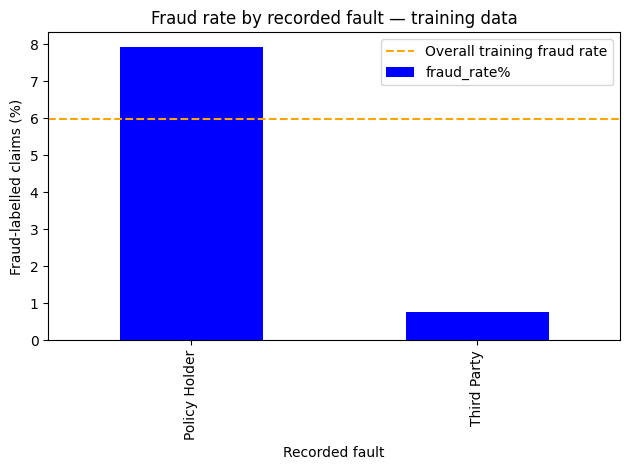

In [41]:
ax = fault_summary["fraud_rate%"].plot(
    kind="bar",
    color="blue",
    #figsize=(7, 4)
)

ax.axhline(
    train_df["FraudFound_P"].mean() * 100,
    color="orange",
    linestyle="--",
    label="Overall training fraud rate"
)

ax.set_title("Fraud rate by recorded fault — training data")
ax.set_xlabel("Recorded fault")
ax.set_ylabel("Fraud-labelled claims (%)")
ax.set_ylim(bottom=0)
ax.legend()

plt.tight_layout()
plt.show()

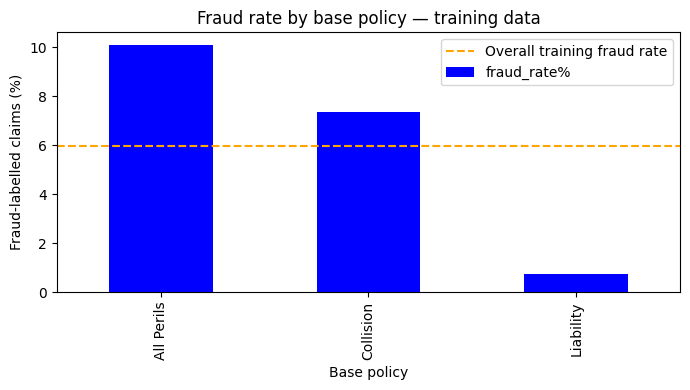

In [42]:
ax = base_policy_summary["fraud_rate%"].plot(
    kind="bar",
    color="blue",
    figsize=(7, 4),
    legend=False
)

ax.axhline(
    train_df["FraudFound_P"].mean() * 100,
    color="orange",
    linestyle="--",
    label="Overall training fraud rate"
)

ax.set_title("Fraud rate by base policy — training data")
ax.set_xlabel("Base policy")
ax.set_ylabel("Fraud-labelled claims (%)")
ax.set_ylim(bottom=0)
ax.legend()

plt.tight_layout()
plt.show()

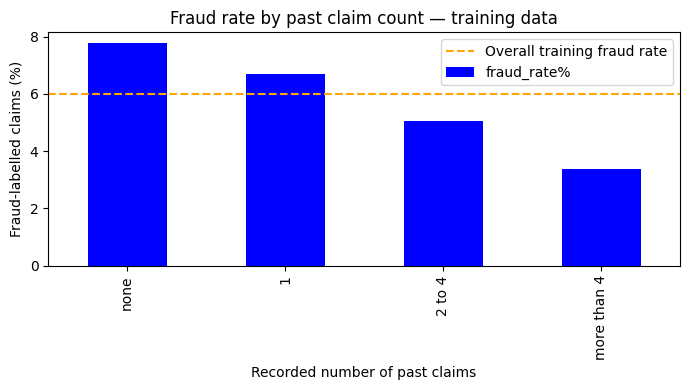

In [43]:
claim_order = ["none", "1", "2 to 4", "more than 4"]

ax = (
    past_claims_summary["fraud_rate%"]
    .reindex(claim_order)
    .plot(
        kind="bar",
        color="blue",
        figsize=(7, 4),
        legend=False
    )
)

ax.axhline(
    train_df["FraudFound_P"].mean() * 100,
    color="orange",
    linestyle="--",
    label="Overall training fraud rate"
)

ax.set_title("Fraud rate by past claim count — training data")
ax.set_xlabel("Recorded number of past claims")
ax.set_ylabel("Fraud-labelled claims (%)")
ax.set_ylim(bottom=0)
ax.legend()

plt.tight_layout()
plt.show()

In [44]:
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

month_summary = (
    train_df.groupby("Month")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
    .reindex(month_order)
)

month_summary["fraud_rate%"] = month_summary["fraud_rate"] * 100

month_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
Month,,,
Jan,837,53,6.332139
Feb,736,53,7.201087
Mar,813,62,7.626076
Apr,764,52,6.806283
May,833,60,7.202881
Jun,796,47,5.904523
Jul,750,34,4.533333
Aug,687,49,7.132460
Sep,758,42,5.540897


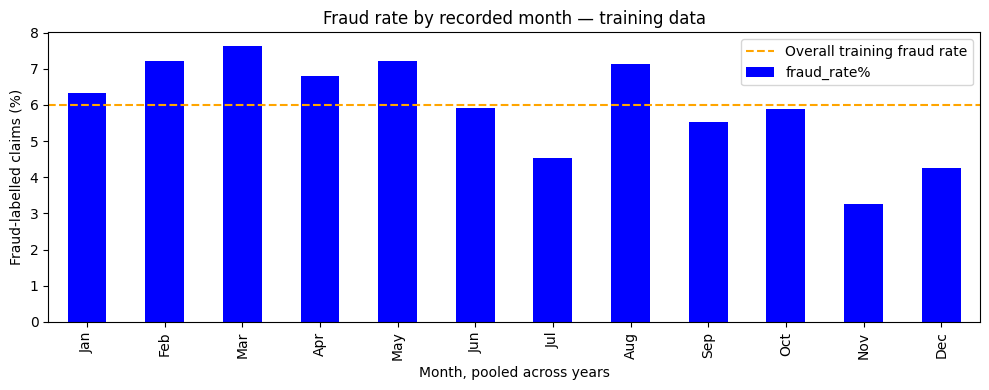

In [45]:
ax = month_summary["fraud_rate%"].plot(
    kind="bar",
    color="blue",
    figsize=(10, 4),
    legend=False
)

ax.axhline(
    train_df["FraudFound_P"].mean() * 100,
    color="orange",
    linestyle="--",
    label="Overall training fraud rate"
)

ax.set_title("Fraud rate by recorded month — training data")
ax.set_xlabel("Month, pooled across years")
ax.set_ylabel("Fraud-labelled claims (%)")
ax.set_ylim(bottom=0)
ax.legend()

plt.tight_layout()
plt.show()

### Training-set fraud-pattern findings

All feature-level fraud comparisons below use training data
only: 9,252 records, including 554 fraud cases (5.99%).
Validation and test data were not used for these comparisons.

- Fault: fraud rates were 7.93% when the policyholder was
  recorded as at fault, versus 0.76% for a third party.
  However, most policyholder-at-fault records were non-fraud.

- BasePolicy: All Perils had the highest rate (10.11%),
  followed by Collision (7.35%) and Liability (0.73%).
  All Perils and Collision each contained 266 fraud cases,
  despite different group sizes.

- VehicleCategory: recorded rates were 12.71% for Utility,
  8.10% for Sedan, and 1.66% for Sport. Utility contained
  only 236 records. The previously identified vehicle-label
  discrepancy limits interpretation as actual vehicle types.

- AgentType: rates were 6.08% for External and 0.65% for
  Internal. The Internal group contained only 154 records
  and one fraud case, limiting confidence in the comparison.

- PoliceReportFiled: rates were 6.03% without a report and
  4.67% with a report. The report-filed group contained
  257 records and 12 fraud cases; the difference alone
  does not establish a reliable relationship.

- PastNumberOfClaims: rates decreased across the recorded
  categories: none (7.76%), one (6.70%), two to four (5.07%),
  and more than four (3.39%).

- Month: pooled monthly rates ranged from 3.27% in November
  to 7.63% in March. This does not establish seasonality
  or a chronological trend.

## Feature availability and leakage review



### Scoring point: initial claim review.

Availability decisions below are assumptions because feature
timing is not documented.

| Feature | Meaning | Available at scoring time? | Decision and reasoning |
|---|---|---|---|
| Fault | Recorded party at fault | Uncertain | Exclude from the primary models because it may reflect a later determination. |
| FraudFound_P | Whether the record is labelled as fraud | Outcome to predict | Use as the target (y), never as a model input (X). |
| PolicyNumber | Unique policy identifier in this dataset | Assumed available | Exclude from model inputs; retain for identifying records and saving split membership. |
| PolicyType | Combined vehicle and coverage label | Assumed yes | Include; policy details are assumed to exist before initial claim review. Preserve original labels despite the documented vehicle-category discrepancy. |
| BasePolicy | Coverage type | Assumed yes | Exclude from primary models because it repeats the coverage information already contained in PolicyType. |
| Deductible | Recorded policy deductible | Assumed yes | Include; assumed to be a policy term known before initial claim review. |
| PoliceReportFiled | Whether a police report is recorded as filed | Assumed yes | Include provisionally, assuming this reflects report status known at initial review rather than a later update. |
| WitnessPresent | Whether a witness is recorded as present | Assumed yes | Include provisionally, assuming witness presence was reported when the claim was submitted. |
| AgentType | Internal or external agent classification | Assumed yes | Include, assuming the agent classification was known at initial review. |
| NumberOfSuppliments | Count category for supplements; exact meaning undocumented | Uncertain | Exclude from primary models because supplements may accumulate during claim processing, after initial review. |
| AddressChange_Claim | Address-change timing category associated with the claim; exact reference point undocumented | Uncertain | Exclude from primary models because its meaning and availability at initial review cannot be established. |
| Age | Recorded age; whose age it represents is not fully documented | Assumed yes | Include provisionally. Treat zero as an unknown age during preprocessing; retain nonzero values without assuming they describe the policyholder. |
| AgeOfPolicyHolder | Recorded policyholder age category | Assumed yes | Exclude from primary models because category labels disagree with observed Age values and their relationship is undocumented. |
| Month | Assumed accident month | Assumed yes | Include, assuming the accident month was reported at claim submission. |
| DayOfWeek | Assumed accident weekday | Assumed yes | Include, assuming the accident weekday was reported at claim submission. |
| WeekOfMonth | Assumed accident week within the month | Assumed yes | Include, assuming this describes the accident timing known at submission. |
| MonthClaimed | Assumed month the claim was submitted | Assumed yes | Include; submission timing should be known at initial review. Treat "0" as missing. |
| DayOfWeekClaimed | Assumed weekday the claim was submitted | Assumed yes | Include; submission timing should be known at initial review. Treat "0" as missing. |
| WeekOfMonthClaimed | Assumed submission week within the month | Assumed yes | Include provisionally; values range from 1 to 5, but the week-numbering convention is undocumented. |
| Days_Policy_Accident | Assumed elapsed-time band between policy start and accident | Assumed yes | Include provisionally, assuming policy start and accident timing were known at submission. Preserve "none" as an ambiguous category. |
| Days_Policy_Claim | Assumed elapsed-time band between policy start and claim | Assumed yes | Include provisionally, assuming policy start and claim timing were known at submission. Preserve "none" as an ambiguous category. |
| PastNumberOfClaims | Recorded previous-claim count category | Assumed yes | Include, assuming it counts claims preceding the current claim and was available at initial review. Interpret "none" as no previous claims. |
| DriverRating | Driver rating code from 1 to 4; scale definition undocumented | Assumed yes | Include provisionally, assuming it is a pre-existing rating rather than one updated after the current claim. Encode as a category without assuming which rating is better. |
| Make | Recorded vehicle manufacturer | Assumed yes | Include; assumed known from policy or submission details. Preserve original category spellings. |
| VehiclePrice | Recorded vehicle-price band; valuation basis undocumented | Assumed yes | Include provisionally, assuming it describes vehicle value known at submission rather than a later settlement valuation. Encode as a category. |
| AgeOfVehicle | Recorded vehicle-age category | Assumed yes | Include, assuming it describes vehicle age at the time of the claim and was known at initial review. |
| VehicleCategory | Recorded vehicle classification | Assumed yes | Exclude from primary models because its labels conflict with PolicyType for 4,987 records. Retain PolicyType without claiming its vehicle labels are verified. |
| AccidentArea | Urban or rural accident-location category | Assumed yes | Include, assuming the location category was reported at submission and was not assigned using later investigation findings. |
| NumberOfCars | Recorded vehicle-count category; whether it refers to a household or policy is undocumented | Assumed yes | Include provisionally, assuming it reflects information held before the current claim. Preserve the original categories without assuming exact counts. |
| RepNumber | Assumed representative identifier | Assumed yes | Exclude from primary model inputs because it identifies a representative rather than a claim characteristic. Retain for an optional grouped evaluation. |
| Year | Recorded year, ranging from 1994 to 1996; event reference undocumented | Uncertain | Exclude from primary model inputs because it is unclear whether this refers to accident, submission, or another event. Retain for descriptive checks. |
| Sex | Recorded sex category | Assumed yes | Exclude from primary models as a scope choice: demographic predictors are outside this initial model's feature set. |
| MaritalStatus | Recorded marital-status category | Assumed yes | Exclude from primary models as a scope choice: demographic predictors are outside this initial model's feature set. |

## Model Training and Validation

In [46]:
age_missing_summary = (
    train_df.assign(age_missing=train_df["Age"].eq(0))
    .groupby("age_missing")["FraudFound_P"]
    .agg(
        records="size",
        fraud_cases="sum",
        fraud_rate="mean"
    )
)

age_missing_summary["fraud_rate%"] = (
    age_missing_summary["fraud_rate"] * 100
)

age_missing_summary[["records", "fraud_cases", "fraud_rate%"]]

,records,fraud_cases,fraud_rate%
age_missing,,,
False,9060,531,5.860927
True,192,23,11.979167


In [47]:
def clean_known_placeholders(data):
    cleaned = data.copy()

    # Record the original zero-age pattern
    cleaned["age_missing"] = cleaned["Age"].eq(0).astype(int)

    # Replace invalid placeholders with missing values
    cleaned["Age"] = cleaned["Age"].replace(0, np.nan)

    for column in ["MonthClaimed", "DayOfWeekClaimed"]:
        cleaned[column] = cleaned[column].replace(["0", 0], np.nan)

    return cleaned


train_clean = clean_known_placeholders(train_df)
validation_clean = clean_known_placeholders(validation_df)
test_clean = clean_known_placeholders(test_df)

In [48]:
print(
    train_clean[
        ["Age", "MonthClaimed", "DayOfWeekClaimed"]
    ].isna().sum()
)

print("\nAge-missing flag counts:")
print(train_clean["age_missing"].value_counts())

Age                 192
MonthClaimed          1
DayOfWeekClaimed      1
dtype: int64

Age-missing flag counts:
age_missing
0    9060
1     192
Name: count, dtype: int64


In [49]:
excluded_features = [
    "PolicyNumber",
    "Fault",
    "BasePolicy",
    "NumberOfSuppliments",
    "AddressChange_Claim",
    "AgeOfPolicyHolder",
    "VehicleCategory",
    "RepNumber",
    "Year",
    "Sex",
    "MaritalStatus"
]

columns_to_drop = excluded_features + ["FraudFound_P"]

X_train = train_clean.drop(columns=columns_to_drop)
y_train = train_clean["FraudFound_P"].copy()

X_validation = validation_clean.drop(columns=columns_to_drop)
y_validation = validation_clean["FraudFound_P"].copy()

X_test = test_clean.drop(columns=columns_to_drop)
y_test = test_clean["FraudFound_P"].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (9252, 22) (9252,)
Validation: (3084, 22) (3084,)
Test: (3084, 22) (3084,)


In [50]:
numeric_features = [
    "Age",
    "Deductible",
    "age_missing"
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

print(
    "\nTotal:",
    len(numeric_features) + len(categorical_features)
)

Numeric features: ['Age', 'Deductible', 'age_missing']

Categorical features: ['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'PolicyType', 'VehiclePrice', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfCars']

Total: 22


In [51]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [52]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        min_frequency=30,
        handle_unknown="infrequent_if_exist"
    ))
])

In [53]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [54]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score

dummy_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DummyClassifier(strategy="prior"))
])

dummy_pipeline.fit(X_train, y_train)

dummy_validation_scores = dummy_pipeline.predict_proba(
    X_validation
)[:, 1]

dummy_ap = average_precision_score(
    y_validation,
    dummy_validation_scores
)

print(f"Dummy validation average precision: {dummy_ap:.4f}")

Dummy validation average precision: 0.0600


In [55]:
from sklearn.linear_model import LogisticRegression as lr

logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", lr(max_iter=1000))
])

logistic_pipeline.fit(X_train, y_train)

logistic_validation_scores = logistic_pipeline.predict_proba(
    X_validation
)[:, 1]

logistic_ap = average_precision_score(
    y_validation,
    logistic_validation_scores
)

print(f"Dummy validation AP: {dummy_ap:.4f}")
print(f"Logistic regression validation AP: {logistic_ap:.4f}")

Dummy validation AP: 0.0600
Logistic regression validation AP: 0.1142


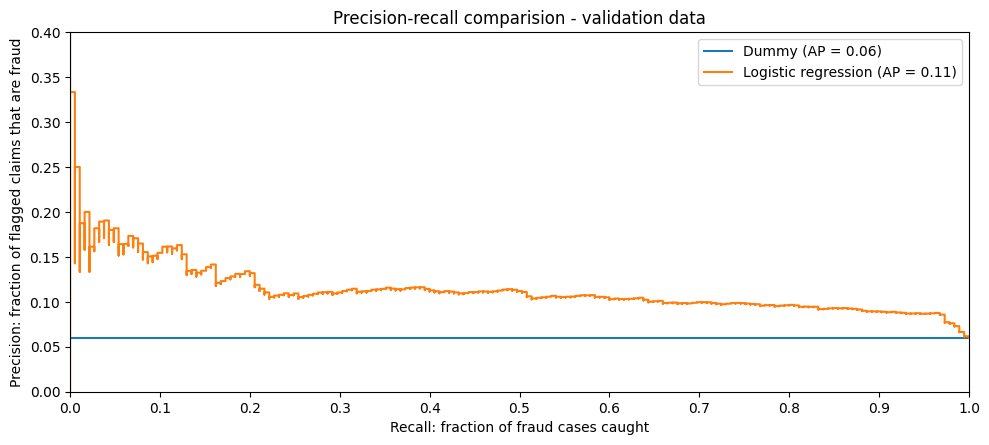

In [56]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(10, 6))

PrecisionRecallDisplay.from_predictions(
    y_validation,
    dummy_validation_scores,
    name=f"Dummy",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_validation,
    logistic_validation_scores,
    name=f"Logistic regression",
    ax=ax
)

ax.set_title("Precision-recall comparision - validation data")
ax.set_xlabel("Recall: fraction of fraud cases caught")
ax.set_ylabel("Precision: fraction of flagged claims that are fraud")
ax.set_xlim(0,1)
ax.set_ylim(0,0.40)
ax.legend(loc="upper right")

ax.set_xticks(np.arange(0, 1.01, 0.1))
plt.tight_layout()
plt.show()

In [57]:
logistic_balalanced_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", lr(max_iter=1000, class_weight="balanced"))
])

logistic_balalanced_pipeline.fit(X_train, y_train)

balanced_validation_scores = (
    logistic_balalanced_pipeline.predict_proba(X_validation)[:,1]
)

balanced_ap = average_precision_score(
    y_validation,
    balanced_validation_scores
)

print(f"Dummy validation AP: {dummy_ap:.4f}")
print(f"Logistic regression validation AP: {logistic_ap:.4f}")
print(f"Logistic regression balanced validation AP: {balanced_ap:.4f}")


Dummy validation AP: 0.0600
Logistic regression validation AP: 0.1142
Logistic regression balanced validation AP: 0.1097


In [58]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

rf_validation_scores = rf_pipeline.predict_proba(
    X_validation
)[:, 1]

rf_ap = average_precision_score(
    y_validation,
    rf_validation_scores
)

print(f"Logistic regression validation AP: {logistic_ap:.4f}")
print(f"Weighted logistic regression validation AP: {balanced_ap:.4f}")
print(f"Random forest validation AP: {rf_ap:.4f}")

Logistic regression validation AP: 0.1142
Weighted logistic regression validation AP: 0.1097
Random forest validation AP: 0.1426


In [59]:
rf_balanced_pipeline = clone(rf_pipeline)

rf_balanced_pipeline.set_params(
    model__class_weight="balanced"
)

rf_balanced_pipeline.fit(X_train, y_train)

rf_balanced_validation_scores = (
    rf_balanced_pipeline.predict_proba(X_validation)[:, 1]
)

rf_balanced_ap = average_precision_score(
    y_validation,
    rf_balanced_validation_scores
)

print(f"Random forest validation AP: {rf_ap:.4f}")
print(f"Weighted random forest validation AP: {rf_balanced_ap:.4f}")

Random forest validation AP: 0.1426
Weighted random forest validation AP: 0.1462


In [60]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score
)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=42
)

cv_scores = cross_val_score(
    clone(rf_balanced_pipeline),
    X_train,
    y_train,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

print("Fold AP scores:", np.round(cv_scores, 4))
print(f"Mean CV AP: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std(ddof=1):.4f}")

Fold AP scores: [0.1368 0.1495 0.1286 0.1347 0.1176 0.1096 0.1889 0.1191 0.1185 0.1382]
Mean CV AP: 0.1342
Standard deviation: 0.0227


### Initial model comparison

All models were fitted on training data. Model comparison
used validation average precision (AP).

| Model | Validation AP |
|---|---:|
| Dummy baseline | 0.0600 |
| Logistic regression | 0.1142 |
| Weighted logistic regression | 0.1097 |
| Random forest | 0.1426 |
| Weighted random forest | 0.1462 |

Weighted random forest achieved the highest validation AP.
Class weighting reduced logistic regression AP but slightly
improved random forest AP.

The forest settings were 300 trees and a minimum of five
training records per leaf. These were starting settings,
not the result of an extensive tuning search.

### Training-only stability check

Weighted random forest was evaluated using five-fold
stratified cross-validation repeated twice within the
training set.

- Mean AP: 0.1342
- Standard deviation across scores: 0.0227
- Minimum AP: 0.1096
- Maximum AP: 0.1889

Preprocessing was fitted separately within each fold.
The spread indicates sensitivity to the learning and
evaluation samples. The standard deviation is descriptive,
not a confidence interval; repeated folds are not independent.

The small validation advantage over unweighted random forest
has not been established as a consistent improvement.

Weighted random forest is selected provisionally for threshold
analysis based on validation AP. AP does not specify precision,
recall, or investigation workload at a particular threshold.

The held-out test set has not been evaluated.

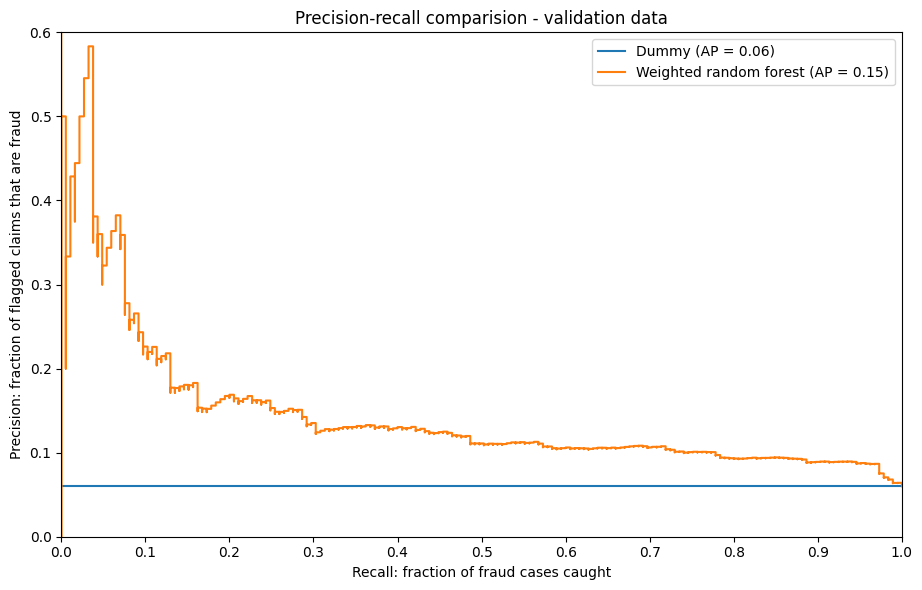

In [61]:
fig, ax = plt.subplots(figsize=(10, 6))

PrecisionRecallDisplay.from_predictions(
    y_validation,
    dummy_validation_scores,
    name="Dummy",
    ax=ax

)

PrecisionRecallDisplay.from_predictions(
    y_validation,
    rf_balanced_validation_scores,
    name="Weighted random forest",
    ax=ax
)

ax.set_title("Precision-recall comparision - validation data")
ax.set_xlabel("Recall: fraction of fraud cases caught")
ax.set_ylabel("Precision: fraction of flagged claims that are fraud")
ax.set_xlim(0,1)
ax.set_ylim(0,0.6)
ax.legend(loc="upper right")

ax.set_xticks(np.arange(0, 1.01, 0.1))

plt.tight_layout()
plt.show()

In [62]:
from sklearn.metrics import confusion_matrix

threshold = 0.26

flagged = rf_balanced_validation_scores >= threshold

tn,fp,fn,tp = confusion_matrix(
    y_validation,
    flagged,
    labels=[0, 1]
).ravel()

precision = tp / (tp +fp) if (tp + fp) > 0 else np.nan
recall = tp / (tp + fn)
review_share = flagged.mean()

print(f"Threshold: {threshold:.2f}")
print(f"TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"Claims flagged for review: {review_share:.2%}")


Threshold: 0.26
TP: 133, FP: 1132, FN: 52, TN: 1767
Precision: 0.11
Recall: 0.72
Claims flagged for review: 41.02%


In [63]:
rows = []

for threshold in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, np.inf]:
    flagged = rf_balanced_validation_scores >= threshold

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        flagged,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision%": 100 * tp / (tp + fp)
                      if (tp + fp) > 0 else np.nan,
        "recall%": 100 * tp / (tp + fn),
        "review%": 100 * flagged.mean()
    })

threshold_table = pd.DataFrame(rows)

threshold_table.round(2)

,threshold,TP,FP,FN,TN,precision%,recall%,review%
0,0.0,185,2899,0,0,6.00,100.00,100.00
1,0.1,180,2053,5,846,8.06,97.30,72.41
2,0.2,164,1630,21,1269,9.14,88.65,58.17
3,0.3,93,753,92,2146,10.99,50.27,27.43
4,0.4,38,188,147,2711,16.81,20.54,7.33
5,0.5,14,27,171,2872,34.15,7.57,1.33
6,inf,0,0,185,2899,NaN,0.00,0.00


In [64]:
threshold_table["cost_1_to_5"] = (
    threshold_table["FP"]
    + 5 * threshold_table["FN"]
)

threshold_table[
    ["threshold", "FP", "FN", "review%", "cost_1_to_5"]
].round(2)

,threshold,FP,FN,review%,cost_1_to_5
0,0.0,2899,0,100.00,2899
1,0.1,2053,5,72.41,2078
2,0.2,1630,21,58.17,1735
3,0.3,753,92,27.43,1213
4,0.4,188,147,7.33,923
5,0.5,27,171,1.33,882
6,inf,0,185,0.00,925


In [65]:
threshold_table["cost_1_to_10"] = (
    threshold_table["FP"]
    + 10 * threshold_table["FN"]
)

threshold_table["cost_1_to_20"] = (
    threshold_table["FP"]
    + 20 * threshold_table["FN"]
)

threshold_table[
    [
        "threshold",
        "review%",
        "cost_1_to_5",
        "cost_1_to_10",
        "cost_1_to_20"
    ]
].round(2)

,threshold,review%,cost_1_to_5,cost_1_to_10,cost_1_to_20
0,0.0,100.00,2899,2899,2899
1,0.1,72.41,2078,2103,2153
2,0.2,58.17,1735,1840,2050
3,0.3,27.43,1213,1673,2593
4,0.4,7.33,923,1658,3128
5,0.5,1.33,882,1737,3447
6,inf,0.00,925,1850,3700


In [66]:
candidate_thresholds = np.append(
    np.unique(rf_balanced_validation_scores),
    np.inf
)

sweep_rows = []

for threshold in candidate_thresholds:
    flagged = rf_balanced_validation_scores >= threshold

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        flagged,
        labels=[0, 1]
    ).ravel()

    sweep_rows.append({
        "threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision%": 100 * tp / (tp + fp)
                      if (tp + fp) > 0 else np.nan,
        "recall%": 100 * tp / (tp + fn),
        "review%": 100 * flagged.mean()
    })

cost_sweep = pd.DataFrame(sweep_rows)

for missed_cost in [5, 10, 20]:
    cost_sweep[f"cost_1_to_{missed_cost}"] = (
        cost_sweep["FP"] + missed_cost * cost_sweep["FN"]
    )

print("Candidate thresholds evaluated:", len(cost_sweep))

Candidate thresholds evaluated: 3085


In [67]:
selected_rows = []

for missed_cost in [5, 10, 20]:
    cost_column = f"cost_1_to_{missed_cost}"

    best = cost_sweep.sort_values(
        by=[cost_column, "review%"]
    ).iloc[0]

    selected_rows.append({
        "cost_ratio": f"1:{missed_cost}",
        "threshold": best["threshold"],
        "TP": int(best["TP"]),
        "FP": int(best["FP"]),
        "FN": int(best["FN"]),
        "precision%": best["precision%"],
        "recall%": best["recall%"],
        "review%": best["review%"],
        "scenario_cost": int(best[cost_column])
    })

scenario_results = pd.DataFrame(selected_rows)

scenario_results.round(4)

,cost_ratio,threshold,TP,FP,FN,precision%,recall%,review%,scenario_cost
0,1:5,0.5095,14,25,171,35.8974,7.5676,1.2646,880
1,1:10,0.3305,78,519,107,13.0653,42.1622,19.3580,1589
2,1:20,0.1721,174,1770,11,8.9506,94.0541,63.0350,1990


In [68]:
scenario_comparison = scenario_results.copy()

missed_costs = scenario_comparison["cost_ratio"].map({
    "1:5": 5,
    "1:10": 10,
    "1:20": 20
})

scenario_comparison["review_none_cost"] = (
    int(y_validation.sum()) * missed_costs
)

scenario_comparison["review_all_cost"] = (
    int((y_validation == 0).sum())
)

scenario_comparison[
    [
        "cost_ratio",
        "scenario_cost",
        "review_none_cost",
        "review_all_cost"
    ]
]

,cost_ratio,scenario_cost,review_none_cost,review_all_cost
0,1:5,880,925,2899
1,1:10,1589,1850,2899
2,1:20,1990,3700,2899


In [69]:
X_train_fault = X_train.assign(
    Fault=train_clean["Fault"]
)

X_validation_fault = X_validation.assign(
    Fault=validation_clean["Fault"]
)

print("Primary training inputs:", X_train.shape)
print("Sensitivity training inputs:", X_train_fault.shape)
print("Sensitivity validation inputs:", X_validation_fault.shape)

Primary training inputs: (9252, 22)
Sensitivity training inputs: (9252, 23)
Sensitivity validation inputs: (3084, 23)


In [70]:
fault_categorical_features = categorical_features + ["Fault"]

fault_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), numeric_features),
    ("categorical", clone(categorical_pipeline),
     fault_categorical_features)
])

fault_sensitivity_pipeline = clone(rf_balanced_pipeline)

fault_sensitivity_pipeline.set_params(
    preprocessor=fault_preprocessor
)

fault_sensitivity_pipeline.fit(X_train_fault, y_train)

fault_validation_scores = (
    fault_sensitivity_pipeline.predict_proba(
        X_validation_fault
    )[:, 1]
)

fault_ap = average_precision_score(
    y_validation,
    fault_validation_scores
)

print(f"Primary model validation AP: {rf_balanced_ap:.4f}")
print(f"With Fault validation AP: {fault_ap:.4f}")
print(f"AP difference: {fault_ap - rf_balanced_ap:+.4f}")

Primary model validation AP: 0.1462
With Fault validation AP: 0.2097
AP difference: +0.0634


In [71]:
feature_names = (
    rf_balanced_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    rf_balanced_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_table = pd.DataFrame({
    "encoded_feature": feature_names,
    "importance": importance_values
})

importance_table = importance_table.sort_values(
    "importance",
    ascending=False
)

importance_table.head(15)

,encoded_feature,importance
68,categorical__PolicyType_Sedan - Liability,0.125529
0,numeric__Age,0.082126
66,categorical__PolicyType_Sedan - All Perils,0.036839
67,categorical__PolicyType_Sedan - Collision,0.028378
91,categorical__PastNumberOfClaims_none,0.017048
72,categorical__VehiclePrice_20000 to 29000,0.016283
97,categorical__AgeOfVehicle_7 years,0.015835
62,categorical__WeekOfMonthClaimed_2,0.014471
98,categorical__AgeOfVehicle_more than 7,0.014371
80,categorical__DriverRating_3,0.014029


### Validation threshold analysis

Thresholds were selected by minimizing FP + c × FN across
every distinct validation score, including the flag-nothing
option. Equal-cost choices favour lower review workload.

| FP:FN cost ratio | Threshold* | Precision | Recall | Review share | Scenario cost |
|---|---:|---:|---:|---:|---:|
| 1:5 | 0.5095 | 35.90% | 7.57% | 1.26% | 880 |
| 1:10 | 0.3305 | 13.07% | 42.16% | 19.36% | 1,589 |
| 1:20 | 0.1721 | 8.95% | 94.05% | 63.04% | 1,990 |

*Thresholds are displayed rounded; full-precision values are
retained in scenario_results.

Each choice had lower validation scenario cost than flagging
nothing or everything. These comparisons use the same data
used to select thresholds and require held-out evaluation.

Costs are hypothetical penalties, not actual financial losses.
The formula omits investigation costs for true-positive claims;
total review workload is therefore reported separately.

### Fault sensitivity and importance review

Adding Fault increased validation AP from 0.1462 to 0.2097.
This demonstrates predictive information, not verified
availability at initial review. Fault remains excluded from
the primary model regardless of this result.

The primary forest's leading individual encoded features
included the Sedan-Liability policy indicator and Age.
DriverRating categories also appeared among leading features.

Importance values describe training split improvements.
They do not establish direction, causation, or absence of
leakage. Numeric-feature bias, correlated inputs, uncertain
field meanings, and availability assumptions remain limitations.

The primary feature set remains unchanged. No test-set
performance has been examined.

## Freeze model and threshold choices

In [72]:
for ratio, threshold in zip(
    scenario_results["cost_ratio"],
    scenario_results["threshold"]
):
    print(f"{ratio}: {threshold:.17g}")

1:5: 0.50949964720280316
1:10: 0.33054037832098099
1:20: 0.17208923258978076


In [73]:
import joblib

frozen_bundle = {
    "pipeline": rf_balanced_pipeline,
    "thresholds": dict(zip(
        scenario_results["cost_ratio"],
        scenario_results["threshold"]
    )),
    "feature_columns": X_train.columns.tolist(),
    "primary_scenario": "1:10",
    "validation_ap": rf_balanced_ap
}

save_path = (
    "/content/drive/MyDrive/Project: trust-safety/"
    "frozen_fraud_model.joblib"
)

joblib.dump(frozen_bundle, save_path)

print(f"Validation AP: {rf_balanced_ap:.4f}")
print("Saved:", save_path)

Validation AP: 0.1462
Saved: /content/drive/MyDrive/Project: trust-safety/frozen_fraud_model.joblib


### Frozen artifact and saved model

The fitted pipeline, thresholds, and input-column list were saved
to Google Drive as frozen_fraud_model.joblib.

Frozen evaluation choices:
- Model: weighted random forest fitted on training data only.
- Inputs: 22 columns before encoding; Fault excluded.
- Primary illustrative scenario: 1:10.
- Alternative scenarios: 1:5 and 1:20.
- Use the saved fitted pipeline and full-precision thresholds.
- Do not refit or adjust thresholds based on test results.

No test-set performance has been examined.

## Held-out test evaluation

In [74]:

from sklearn.metrics import average_precision_score

frozen_bundle = joblib.load(
    "/content/drive/MyDrive/Project: trust-safety/"
    "frozen_fraud_model.joblib"
)

frozen_model = frozen_bundle["pipeline"]

assert X_test.columns.tolist() == frozen_bundle["feature_columns"]

test_scores = frozen_model.predict_proba(X_test)[:, 1]

test_ap = average_precision_score(y_test, test_scores)

print(f"Validation AP: {frozen_bundle['validation_ap']:.4f}")
print(f"Test AP: {test_ap:.4f}")

Validation AP: 0.1462
Test AP: 0.1247


In [75]:
from sklearn.metrics import confusion_matrix

test_rows = []

for ratio, threshold in frozen_bundle["thresholds"].items():
    flagged = test_scores >= threshold

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        flagged,
        labels=[0, 1]
    ).ravel()

    test_rows.append({
        "cost_ratio": ratio,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision%": 100 * tp / (tp + fp)
                      if (tp + fp) > 0 else np.nan,
        "recall%": 100 * tp / (tp + fn),
        "review%": 100 * flagged.mean()
    })

test_results = pd.DataFrame(test_rows)

test_results.round(2)

,cost_ratio,TP,FP,FN,TN,precision%,recall%,review%
0,1:5,8,33,176,2867,19.51,4.35,1.33
1,1:10,73,530,111,2370,12.11,39.67,19.55
2,1:20,163,1768,21,1132,8.44,88.59,62.61


In [76]:
missed_costs = test_results["cost_ratio"].map({
    "1:5": 5,
    "1:10": 10,
    "1:20": 20
})

test_results["fraud_caught_per_1000"] = (
    1000 * test_results["TP"] / len(y_test)
)

test_results["fraud_missed_per_1000"] = (
    1000 * test_results["FN"] / len(y_test)
)

test_results["scenario_cost"] = (
    test_results["FP"]
    + missed_costs * test_results["FN"]
)

test_results["review_none_cost"] = (
    int(y_test.sum()) * missed_costs
)

test_results["review_all_cost"] = int((y_test == 0).sum())

test_results[
    [
        "cost_ratio",
        "fraud_caught_per_1000",
        "fraud_missed_per_1000",
        "scenario_cost",
        "review_none_cost",
        "review_all_cost"
    ]
].round(2)

,cost_ratio,fraud_caught_per_1000,fraud_missed_per_1000,scenario_cost,review_none_cost,review_all_cost
0,1:5,2.59,57.07,913,920,2900
1,1:10,23.67,35.99,1640,1840,2900
2,1:20,52.85,6.81,2188,3680,2900


### Held-out test findings

The frozen weighted random forest and validation-selected
thresholds were evaluated on 3,084 test claims containing
184 fraud cases (5.97%). No fitting or threshold adjustment
was performed using test results.

Test average precision was 0.1247, below validation AP
of 0.1462.

### Frozen operating points

| Cost ratio | Precision | Recall | Review share | Scenario cost |
|---|---:|---:|---:|---:|
| 1:5 | 19.51% | 4.35% | 1.33% | 913 |
| 1:10 | 12.11% | 39.67% | 19.55% | 1,640 |
| 1:20 | 8.44% | 88.59% | 62.61% | 2,188 |

### Primary illustrative scenario: 1:10

Reviewing approximately 20% of test claims caught approximately
40% of fraud, at 12.11% precision.

Of 603 flagged claims:
- 73 were fraud.
- 530 were non-fraud.

The model missed 111 fraud cases and correctly left 2,370
non-fraud claims unflagged.

Per 1,000 total claims, this corresponds to:
- 23.67 fraud cases detected.
- 35.99 fraud cases missed.

Precision and recall were lower than validation results
(13.07% precision and 42.16% recall), with similar review workload.

### Scenario-cost comparison

| Cost ratio | Model cost | Flag nothing | Flag everything |
|---|---:|---:|---:|
| 1:5 | 913 | 920 | 2,900 |
| 1:10 | 1,640 | 1,840 | 2,900 |
| 1:20 | 2,188 | 3,680 | 2,900 |

All three operating points had lower observed test scenario
cost than either simple alternative. At 1:5, the improvement
was only seven units and rested on eight detected fraud cases.

Costs are illustrative penalties, not verified financial losses.
They omit investigation costs for true-positive claims.

The results support a workload-versus-detection comparison,
not production deployment or automatic claim rejection.
Thresholds remain unchanged after test evaluation.